### Import dan setup path

In [4]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from sklearn.metrics.pairwise import euclidean_distances

warnings.filterwarnings("ignore", category=FutureWarning)

current = Path(os.getcwd())
if (current / "data").exists():
    BASE_DIR = current
elif (current.parent / "data").exists():
    BASE_DIR = current.parent
else:
    raise FileNotFoundError("Folder 'data' tidak ditemukan, cek lokasi notebook")

CLEAN_DIR = BASE_DIR / "data" / "clean"
ANALYTICS_DIR = BASE_DIR / "data" / "analytics"
ANALYTICS_DIR.mkdir(parents=True, exist_ok=True)

print("CLEAN_DIR     :", CLEAN_DIR)
print("ANALYTICS_DIR :", ANALYTICS_DIR)

CLEAN_DIR     : c:\KULIAH\SEM 5\Project Analitika Data\data\clean
ANALYTICS_DIR : c:\KULIAH\SEM 5\Project Analitika Data\data\analytics


### Baca matriks responden * aspek

In [5]:
df_skor = pd.read_csv(CLEAN_DIR / "skor_aspek_mahasiswa.csv")
print("Shape:", df_skor.shape)

print("\nProporsi data kosong per kolom:")
print(df_skor.isnull().mean().round(2))

Shape: (418, 13)

Proporsi data kosong per kolom:
response_id                        0.00
Administrasi Akademik              0.00
Kemahasiswaan                      0.00
Administrasi Keuangan              0.00
Administrasi Umum                  0.00
Ruang Kuliah                       0.00
Laboratorium                       0.00
Perpustakaan                       0.00
TIK dan Sistem Informasi kampus    0.00
Toilet kampus                      0.00
Parkir kampus                      0.00
Lingkungan Kampus                  0.00
Klinik Kampus                      0.72
dtype: float64


### Siapkan Matriks (buang kolom bersyarat dan baris kosong)

In [6]:
kolom_aspek = [k for k in df_skor.columns if k != "response_id"]

# kolom yang kosong lebih dari 50% (misal Klinik) tidak dipakai di MDS
kolom_dibuang = []
for kolom in kolom_aspek:
    if df_skor[kolom].isnull().mean() > 0.5:
        kolom_dibuang.append(kolom)

kolom_aspek = [k for k in kolom_aspek if k not in kolom_dibuang]
print("Kolom dibuang :", kolom_dibuang)
print("Aspek dipakai :", kolom_aspek)

# buang responden yang masih punya nilai kosong
df_matriks = df_skor[["response_id"] + kolom_aspek].dropna().reset_index(drop=True)
print("Responden dipakai:", len(df_matriks), "dari", len(df_skor))

X = df_matriks[kolom_aspek].values

Kolom dibuang : ['Klinik Kampus']
Aspek dipakai : ['Administrasi Akademik', 'Kemahasiswaan', 'Administrasi Keuangan', 'Administrasi Umum', 'Ruang Kuliah', 'Laboratorium', 'Perpustakaan', 'TIK dan Sistem Informasi kampus', 'Toilet kampus', 'Parkir kampus', 'Lingkungan Kampus']
Responden dipakai: 418 dari 418


### Matriks jarak dan fungsi stress

In [7]:
# semua aspek sudah di skala 1-4, jadi tidak perlu standardisasi
jarak_asli = euclidean_distances(X)

def hitung_stress1(jarak_asli, koordinat):
    # Kruskal stress-1: makin kecil makin bagus
    jarak_hasil = euclidean_distances(koordinat)
    atas = np.sum((jarak_asli - jarak_hasil) ** 2)
    bawah = np.sum(jarak_asli ** 2)
    return np.sqrt(atas / bawah)

def interpretasi_stress(nilai):
    # pedoman kasar
    if nilai < 0.05:
        return "sangat baik"
    elif nilai < 0.10:
        return "baik"
    elif nilai < 0.20:
        return "cukup"
    else:
        return "kurang baik"

### Pilih jumlah stress (elbow stress)

Dimensi 1 | stress-1 = 0.3878
Dimensi 2 | stress-1 = 0.1784
Dimensi 3 | stress-1 = 0.1092
Dimensi 4 | stress-1 = 0.074
Dimensi 5 | stress-1 = 0.0512


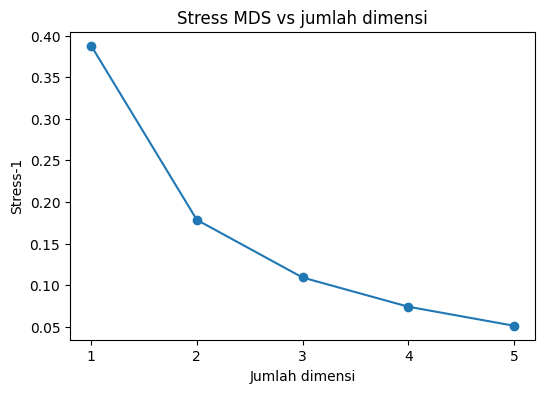

In [8]:
daftar_dimensi = [1, 2, 3, 4, 5]
daftar_stress = []

for k in daftar_dimensi:
    mds = MDS(n_components=k, dissimilarity="precomputed", n_init=4, random_state=42)
    koordinat_k = mds.fit_transform(jarak_asli)
    stress_k = hitung_stress1(jarak_asli, koordinat_k)
    daftar_stress.append(stress_k)
    print("Dimensi", k, "| stress-1 =", round(stress_k, 4))

plt.figure(figsize=(6, 4))
plt.plot(daftar_dimensi, daftar_stress, marker="o")
plt.xlabel("Jumlah dimensi")
plt.ylabel("Stress-1")
plt.title("Stress MDS vs jumlah dimensi")
plt.xticks(daftar_dimensi)
plt.show()

### MDS 2 dimensi untuk responden

In [9]:
mds_2d = MDS(n_components=2, dissimilarity="precomputed", n_init=4, random_state=42)
koordinat = mds_2d.fit_transform(jarak_asli)

stress_responden = hitung_stress1(jarak_asli, koordinat)
print("Stress-1 (responden):", round(stress_responden, 4), "->", interpretasi_stress(stress_responden))

df_koordinat = pd.DataFrame({
    "response_id": df_matriks["response_id"],
    "dim1": koordinat[:, 0].round(4),
    "dim2": koordinat[:, 1].round(4)
})
df_koordinat.head()

Stress-1 (responden): 0.1784 -> cukup


,response_id,dim1,dim2
0,MHS_0001,2.6642,1.5907
1,MHS_0002,1.1864,-0.6856
2,MHS_0003,2.6107,1.9153
3,MHS_0004,0.0823,-1.0897
4,MHS_0005,-0.4194,-0.4743


### Perceptual map responden (warna per program studi)

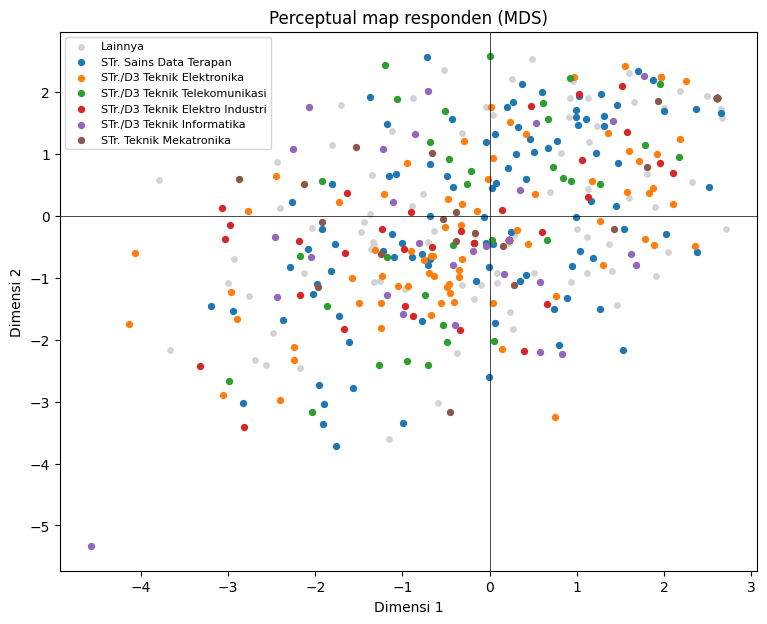

In [10]:
df_profil = pd.read_csv(CLEAN_DIR / "likert_mahasiswa_utama_clean.csv",
                        usecols=["response_id", "Program Studi"])
df_peta = df_koordinat.merge(df_profil, on="response_id", how="left")

top_prodi = df_peta["Program Studi"].value_counts().head(6).index.tolist()

plt.figure(figsize=(9, 7))
sisanya = df_peta[~df_peta["Program Studi"].isin(top_prodi)]
plt.scatter(sisanya["dim1"], sisanya["dim2"], color="lightgray", s=15, label="Lainnya")

for prodi in top_prodi:
    sub = df_peta[df_peta["Program Studi"] == prodi]
    plt.scatter(sub["dim1"], sub["dim2"], s=18, label=prodi)

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Dimensi 1")
plt.ylabel("Dimensi 2")
plt.title("Perceptual map responden (MDS)")
plt.legend(fontsize=8, loc="best")
plt.show()

### Vektor aspek (overlay post-hoc)

                              aspek  korelasi_dim1  korelasi_dim2
0             Administrasi Akademik          0.664          0.812
1                     Kemahasiswaan          0.640          0.817
2             Administrasi Keuangan          0.598          0.783
3                 Administrasi Umum          0.652          0.831
4                      Ruang Kuliah          0.704          0.698
5                      Laboratorium          0.675          0.678
6                      Perpustakaan          0.584          0.745
7   TIK dan Sistem Informasi kampus          0.818          0.503
8                     Toilet kampus          0.721          0.584
9                     Parkir kampus          0.834          0.569
10                Lingkungan Kampus          0.669          0.659


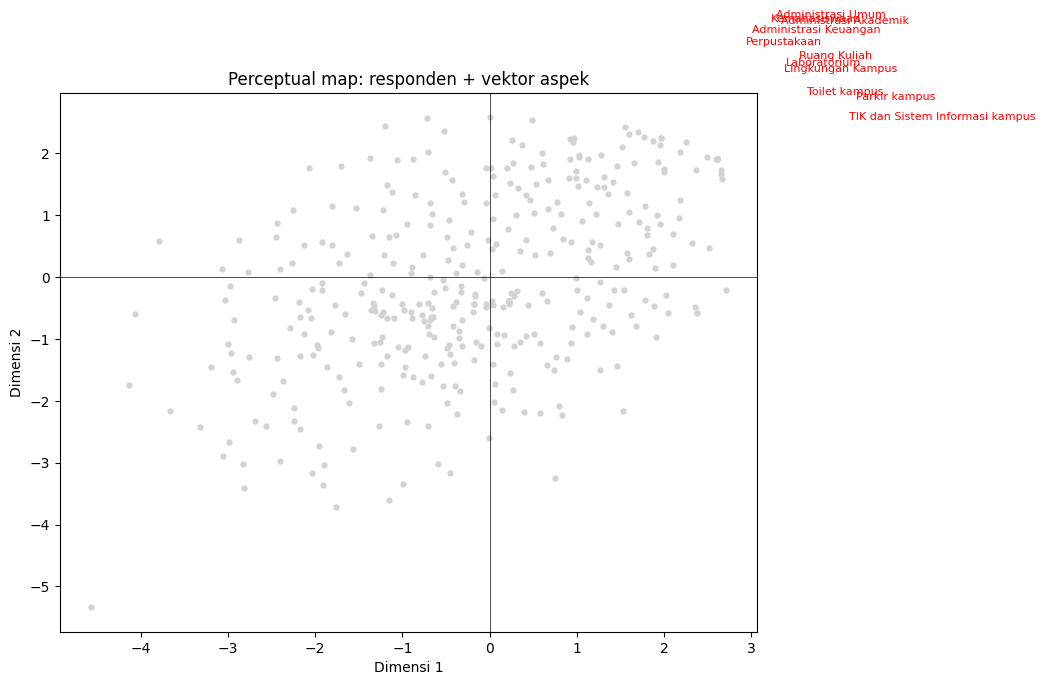

In [11]:
# korelasi skor tiap aspek dengan dimensi 1 dan dimensi 2
daftar_vektor = []
for kolom in kolom_aspek:
    r1 = np.corrcoef(df_matriks[kolom], koordinat[:, 0])[0, 1]
    r2 = np.corrcoef(df_matriks[kolom], koordinat[:, 1])[0, 1]
    daftar_vektor.append({
        "aspek": kolom,
        "korelasi_dim1": round(r1, 3),
        "korelasi_dim2": round(r2, 3)
    })

df_vektor = pd.DataFrame(daftar_vektor)
print(df_vektor)

skala = np.abs(koordinat).max() * 0.9

plt.figure(figsize=(9, 7))
plt.scatter(koordinat[:, 0], koordinat[:, 1], color="lightgray", s=12)

for _, baris in df_vektor.iterrows():
    x = baris["korelasi_dim1"] * skala
    y = baris["korelasi_dim2"] * skala
    plt.annotate("", xy=(x, y), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="->", color="red"))
    plt.text(x * 1.05, y * 1.05, baris["aspek"], color="red", fontsize=8)

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Dimensi 1")
plt.ylabel("Dimensi 2")
plt.title("Perceptual map: responden + vektor aspek")
plt.show()

### MDS titik = aspek (kedekatan antar aspek)

Stress-1 (aspek): 0.2315 -> kurang baik


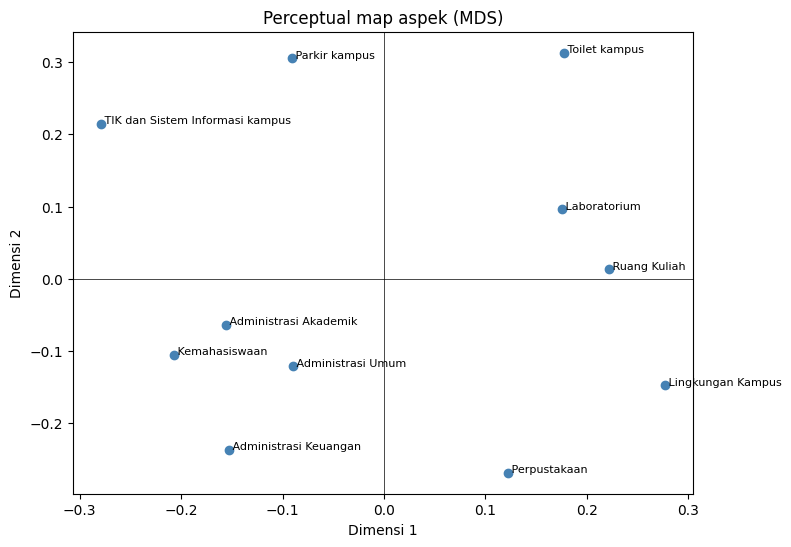

In [12]:
# jarak antar aspek = 1 - korelasi antar aspek
korelasi = np.corrcoef(df_matriks[kolom_aspek].values.T)
jarak_aspek = 1 - korelasi
jarak_aspek = (jarak_aspek + jarak_aspek.T) / 2
jarak_aspek = np.clip(jarak_aspek, 0, None)
np.fill_diagonal(jarak_aspek, 0)

mds_aspek = MDS(n_components=2, dissimilarity="precomputed", n_init=10, random_state=42)
koordinat_aspek = mds_aspek.fit_transform(jarak_aspek)

stress_aspek = hitung_stress1(jarak_aspek, koordinat_aspek)
print("Stress-1 (aspek):", round(stress_aspek, 4), "->", interpretasi_stress(stress_aspek))

df_titik_aspek = pd.DataFrame({
    "aspek": kolom_aspek,
    "dim1": koordinat_aspek[:, 0].round(4),
    "dim2": koordinat_aspek[:, 1].round(4)
})

plt.figure(figsize=(8, 6))
plt.scatter(df_titik_aspek["dim1"], df_titik_aspek["dim2"], color="steelblue")
for _, baris in df_titik_aspek.iterrows():
    plt.text(baris["dim1"], baris["dim2"], " " + baris["aspek"], fontsize=8)
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Dimensi 1")
plt.ylabel("Dimensi 2")
plt.title("Perceptual map aspek (MDS)")
plt.show()

### Simpan hasil -> /data/analytics

In [13]:
df_stress = pd.DataFrame({
    "analisis": ["mds_responden_2d", "mds_aspek_2d"],
    "stress1": [round(stress_responden, 4), round(stress_aspek, 4)],
    "interpretasi": [interpretasi_stress(stress_responden), interpretasi_stress(stress_aspek)]
})

df_koordinat.to_csv(ANALYTICS_DIR / "mds_responden_mahasiswa.csv", index=False)
df_vektor.to_csv(ANALYTICS_DIR / "mds_vektor_aspek_mahasiswa.csv", index=False)
df_titik_aspek.to_csv(ANALYTICS_DIR / "mds_titik_aspek_mahasiswa.csv", index=False)
df_stress.to_csv(ANALYTICS_DIR / "mds_stress_mahasiswa.csv", index=False)

print("Tersimpan di:", ANALYTICS_DIR)
df_stress

Tersimpan di: c:\KULIAH\SEM 5\Project Analitika Data\data\analytics


,analisis,stress1,interpretasi
0,mds_responden_2d,0.1784,cukup
1,mds_aspek_2d,0.2315,kurang baik
